# Hậu xử lý `endocarp`: hull cục bộ trong vùng thịt đỏ

Notebook này chỉ so sánh hai kết quả:

1. **Pipeline hiện tại** trong `src/segment.py`.
2. **Đề xuất mới**: giữ mọi connected component `endocarp`, đóng khe trên dưới cuống, rồi nối lần lượt từng cặp vùng lân cận bằng các cạnh của convex hull cục bộ.

Vùng hợp lệ của kết quả mới là:

```text
allowed_roi = mask_chili - mask_outer - dilated(mask_stem)
```

Seed và placenta được phép chồng với `endocarp`. Không tô convex hull toàn cục và không sửa pipeline production.


In [ ]:
from pathlib import Path
import warnings

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.detect import DetectModel
from src.object import Chili
from src.segment import SegmentModel

warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "runs" / "endocarp_straight_bridge"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

all_image_paths = sorted(DATA_DIR.glob("*.jpg"))
if len(all_image_paths) < 4:
    raise RuntimeError("Cần ít nhất 4 ảnh JPG trong data/ để chạy notebook.")

SAMPLE_PATHS = all_image_paths[:4]
DEVICE = 0 if torch.cuda.is_available() else "cpu"

detector = DetectModel(model_name="none")
segmenter = SegmentModel(
    weight_path=str(ROOT / "pretrain" / "yolov8_segment_v1.pt"),
    model_name="yolo",
    device=DEVICE,
)

print("Device:", DEVICE)
print("Ảnh kiểm thử:", [path.name for path in SAMPLE_PATHS])


## Thuật toán

### 1. ROI và đường đóng khe trên

- `mask_stem` được giãn tối thiểu 2 px để đoạn nối không chạm sát cuống.
- Mask thô được cắt theo `allowed_roi` trước khi xử lý.
- Quét từ đáy cuống xuống để tìm hàng cao nhất có hai mép trong; đoạn nối dày 3 px phải nằm hoàn toàn trong ROI.
- Chỉ fill component lỗ mới xuất hiện và tiếp xúc với đoạn nối này.

### 2. Hull cục bộ theo từng cặp

- Label toàn bộ connected component, không lọc theo diện tích.
- Với mỗi cặp, tính convex hull trên hai contour nhưng chỉ giữ cạnh hull có hai đầu thuộc hai component khác nhau.
- Hai cạnh chéo cùng contour gốc tạo biên khép kín; chỉ vùng lỗ mới do các cạnh này tạo ra được fill.
- Chọn cặp hợp lệ gần nhau nhất, merge, label lại và lặp tới khi còn một component.
- Nếu không còn cặp có cạnh thẳng nằm trọn trong ROI, trả về `unresolved` thay vì vẽ xuyên cuống hoặc ra ngoài quả.


In [ ]:
LINE_THICKNESS = 3
STEM_CLEARANCE_RATIO = 0.008
MINIMUM_GAP_RATIO = 0.025
TOP_SEARCH_DEPTH_RATIO = 0.60


def as_binary(mask):
    return ((mask > 0).astype(np.uint8) * 255)


def component_count(mask):
    count, _ = cv2.connectedComponents((mask > 0).astype(np.uint8), connectivity=8)
    return max(0, count - 1)


def component_masks(mask):
    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        (mask > 0).astype(np.uint8), connectivity=8
    )
    components = []
    for component_id in range(1, count):
        component = ((labels == component_id).astype(np.uint8) * 255)
        components.append({
            "label": component_id,
            "mask": component,
            "area": int(stats[component_id, cv2.CC_STAT_AREA]),
        })
    return components


def union_raw_class_mask(segmentation_result, class_id=3):
    """OR các mask YOLO thô của class, trước hậu xử lý polygon."""
    width, height = segmentation_result["image_size"]
    union = np.zeros((height, width), dtype=np.uint8)
    for item in segmentation_result.get("masks_data", []):
        if item["class_id"] == class_id:
            union = cv2.bitwise_or(union, as_binary(item["mask"]))
    return union


def overlay(image, mask, color, alpha=0.42):
    result = image.copy()
    active = mask > 0
    color_array = np.asarray(color, dtype=np.float32)
    result[active] = (
        result[active].astype(np.float32) * (1.0 - alpha)
        + color_array * alpha
    ).astype(np.uint8)
    return result


def colorize_components(image, mask, alpha=0.55):
    palette = [
        (0, 220, 220), (255, 170, 0), (80, 220, 80), (200, 80, 255),
        (80, 140, 255), (255, 80, 120), (180, 220, 50), (60, 220, 180),
    ]
    result = image.copy()
    for index, component in enumerate(component_masks(mask)):
        result = overlay(result, component["mask"], palette[index % len(palette)], alpha)
    return result


def build_allowed_roi(chili_mask, outer_mask, stem_mask, clearance_ratio=STEM_CLEARANCE_RATIO):
    height, width = chili_mask.shape
    clearance_px = max(2, int(round(min(height, width) * clearance_ratio)))
    kernel_size = 2 * clearance_px + 1
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (kernel_size, kernel_size)
    )
    stem_guard = cv2.dilate(as_binary(stem_mask), kernel)

    allowed = as_binary(chili_mask)
    allowed[as_binary(outer_mask) > 0] = 0
    allowed[stem_guard > 0] = 0
    return allowed, stem_guard, clearance_px


def enclosed_holes(mask):
    """Các background component không nối được với biên ảnh."""
    binary = as_binary(mask)
    padded = cv2.copyMakeBorder(binary, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
    flooded = padded.copy()
    flood_mask = np.zeros(
        (padded.shape[0] + 2, padded.shape[1] + 2), dtype=np.uint8
    )
    cv2.floodFill(flooded, flood_mask, (0, 0), 255)
    holes = cv2.bitwise_not(flooded)[1:-1, 1:-1]
    holes[binary > 0] = 0
    return holes


def newly_enclosed_fill(base_mask, connector_mask, allowed_roi):
    """Chỉ fill lỗ mới được connector hiện tại đóng kín."""
    base = as_binary(base_mask)
    connector = cv2.bitwise_and(as_binary(connector_mask), as_binary(allowed_roi))
    closed = cv2.bitwise_or(base, connector)

    holes_before = enclosed_holes(base)
    holes_after = enclosed_holes(closed)
    new_holes = cv2.bitwise_and(holes_after, cv2.bitwise_not(holes_before))
    new_holes = cv2.bitwise_and(new_holes, as_binary(allowed_roi))

    # Chỉ nhận hole component tiếp xúc với connector vừa thêm.
    contact = cv2.dilate(connector, np.ones((3, 3), dtype=np.uint8))
    count, labels, _, _ = cv2.connectedComponentsWithStats(
        (new_holes > 0).astype(np.uint8), connectivity=8
    )
    selected = np.zeros_like(base)
    for component_id in range(1, count):
        component = labels == component_id
        if np.any(component & (contact > 0)):
            selected[component] = 255

    result = cv2.bitwise_or(closed, selected)
    result = cv2.bitwise_and(result, as_binary(allowed_roi))
    return result, selected


def find_highest_valid_top_bridge(
    endocarp_mask,
    stem_guard,
    allowed_roi,
    line_thickness=LINE_THICKNESS,
    minimum_gap_ratio=MINIMUM_GAP_RATIO,
    search_depth_ratio=TOP_SEARCH_DEPTH_RATIO,
):
    endocarp = cv2.bitwise_and(as_binary(endocarp_mask), as_binary(allowed_roi))
    ys, xs = np.where(endocarp > 0)
    guard_ys, guard_xs = np.where(stem_guard > 0)
    empty = np.zeros_like(endocarp)

    if len(xs) == 0:
        return None, None, empty, {"reason": "empty_endocarp"}
    if len(guard_xs) == 0:
        return None, None, empty, {"reason": "empty_stem"}

    stem_bottom = int(guard_ys.max())
    center_x = int(round(np.median(guard_xs)))
    endocarp_top = int(ys.min())
    endocarp_bottom = int(ys.max())
    object_height = max(1, endocarp_bottom - endocarp_top + 1)
    half_line = (line_thickness + 1) // 2
    first_y = stem_bottom + half_line + 1
    last_y = min(
        endocarp_bottom,
        max(first_y, endocarp_top + int(round(object_height * search_depth_ratio))),
    )
    minimum_gap = max(
        line_thickness + 2,
        int(round((xs.max() - xs.min() + 1) * minimum_gap_ratio)),
    )

    for y in range(first_y, last_y + 1):
        row_x = np.flatnonzero(endocarp[y] > 0)
        left = row_x[row_x < center_x]
        right = row_x[row_x > center_x]
        if len(left) == 0 or len(right) == 0:
            continue

        left_point = np.array([int(left.max()), y], dtype=np.int32)
        right_point = np.array([int(right.min()), y], dtype=np.int32)
        if right_point[0] - left_point[0] < minimum_gap:
            continue
        if np.any(endocarp[y, left_point[0] + 1:right_point[0]] > 0):
            continue

        bridge = np.zeros_like(endocarp)
        cv2.line(
            bridge, tuple(left_point), tuple(right_point), 255,
            thickness=line_thickness, lineType=cv2.LINE_8,
        )
        bridge_pixels = bridge > 0
        if np.any(as_binary(allowed_roi)[bridge_pixels] == 0):
            continue
        if np.any((bridge > 0) & (stem_guard > 0)):
            continue

        endpoints_valid = bool(
            endocarp[left_point[1], left_point[0]] > 0
            and endocarp[right_point[1], right_point[0]] > 0
        )
        return left_point, right_point, bridge, {
            "reason": "ok",
            "stem_bottom": stem_bottom,
            "bridge_y": y,
            "left_point": left_point.tolist(),
            "right_point": right_point.tolist(),
            "endpoints_valid": endpoints_valid,
        }

    return None, None, empty, {
        "reason": "no_valid_top_bridge",
        "stem_bottom": stem_bottom,
        "search_y": (first_y, last_y),
    }


def contour_points(component_mask):
    contours, _ = cv2.findContours(
        as_binary(component_mask), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE
    )
    if not contours:
        return np.empty((0, 2), dtype=np.int32)
    return np.vstack([contour.reshape(-1, 2) for contour in contours]).astype(np.int32)


def minimum_component_distance(mask_a, mask_b):
    distance_to_b = cv2.distanceTransform(
        (mask_b == 0).astype(np.uint8), cv2.DIST_L2, 5
    )
    values = distance_to_b[mask_a > 0]
    return float(values.min()) if len(values) else float("inf")


def pairwise_hull_candidate(mask_a, mask_b, allowed_roi, line_thickness=LINE_THICKNESS):
    """Lấy riêng các cạnh convex hull chuyển từ component A sang B hoặc ngược lại."""
    points_a = contour_points(mask_a)
    points_b = contour_points(mask_b)
    if len(points_a) < 2 or len(points_b) < 2:
        return None

    points = np.vstack([points_a, points_b])
    owners = np.concatenate([
        np.zeros(len(points_a), dtype=np.uint8),
        np.ones(len(points_b), dtype=np.uint8),
    ])
    hull_indices = cv2.convexHull(
        points.reshape(-1, 1, 2), returnPoints=False
    )
    if hull_indices is None or len(hull_indices) < 3:
        return None
    hull_indices = hull_indices.reshape(-1)

    cross_edges = []
    seen = set()
    for index, first_idx in enumerate(hull_indices):
        second_idx = hull_indices[(index + 1) % len(hull_indices)]
        if owners[first_idx] == owners[second_idx]:
            continue
        first = points[first_idx].astype(np.int32)
        second = points[second_idx].astype(np.int32)
        key = tuple(sorted((tuple(first), tuple(second))))
        if key in seen:
            continue
        seen.add(key)
        cross_edges.append((first, second, int(owners[first_idx]), int(owners[second_idx])))

    # Một vùng pairwise khép kín cần hai cạnh chuyển component.
    if len(cross_edges) < 2:
        return None

    connector = np.zeros_like(mask_a)
    endpoint_records = []
    total_length = 0.0
    for first, second, first_owner, second_owner in cross_edges:
        edge = np.zeros_like(mask_a)
        cv2.line(
            edge, tuple(first), tuple(second), 255,
            thickness=line_thickness, lineType=cv2.LINE_8,
        )
        active = edge > 0
        if np.any(as_binary(allowed_roi)[active] == 0):
            return None

        first_mask = mask_a if first_owner == 0 else mask_b
        second_mask = mask_a if second_owner == 0 else mask_b
        endpoints_valid = bool(
            first_mask[first[1], first[0]] > 0
            and second_mask[second[1], second[0]] > 0
        )
        if not endpoints_valid:
            return None

        connector = cv2.bitwise_or(connector, edge)
        total_length += float(np.linalg.norm(first.astype(float) - second.astype(float)))
        endpoint_records.append({
            "first": first.tolist(),
            "second": second.tolist(),
            "first_owner": first_owner,
            "second_owner": second_owner,
            "valid": endpoints_valid,
        })

    pair_base = cv2.bitwise_or(mask_a, mask_b)
    pair_result, local_fill = newly_enclosed_fill(pair_base, connector, allowed_roi)
    if component_count(pair_result) != 1:
        return None

    return {
        "connector": connector,
        "local_fill": local_fill,
        "pair_result": pair_result,
        "distance": minimum_component_distance(mask_a, mask_b),
        "total_edge_length": total_length,
        "edges": endpoint_records,
    }


def connect_all_components(mask, allowed_roi, line_thickness=LINE_THICKNESS):
    """Merge cặp hull hợp lệ gần nhất, label lại sau mỗi lần merge."""
    working = cv2.bitwise_and(as_binary(mask), as_binary(allowed_roi))
    connector_union = np.zeros_like(working)
    fill_union = np.zeros_like(working)
    merge_log = []

    while component_count(working) > 1:
        components = component_masks(working)
        candidates = []
        for first_index in range(len(components)):
            for second_index in range(first_index + 1, len(components)):
                candidate = pairwise_hull_candidate(
                    components[first_index]["mask"],
                    components[second_index]["mask"],
                    allowed_roi,
                    line_thickness=line_thickness,
                )
                if candidate is None:
                    continue
                candidate["first_index"] = first_index
                candidate["second_index"] = second_index
                candidates.append(candidate)

        if not candidates:
            break

        selected = min(
            candidates,
            key=lambda item: (
                item["distance"], item["total_edge_length"],
                item["first_index"], item["second_index"],
            ),
        )
        before_count = component_count(working)
        addition = cv2.bitwise_or(selected["connector"], selected["local_fill"])
        candidate_working = cv2.bitwise_or(working, addition)
        candidate_working = cv2.bitwise_and(candidate_working, as_binary(allowed_roi))
        after_count = component_count(candidate_working)
        if after_count >= before_count:
            break

        working = candidate_working
        connector_union = cv2.bitwise_or(connector_union, selected["connector"])
        fill_union = cv2.bitwise_or(fill_union, selected["local_fill"])
        merge_log.append({
            "before_components": before_count,
            "after_components": after_count,
            "distance": selected["distance"],
            "total_edge_length": selected["total_edge_length"],
            "edges": selected["edges"],
        })

    return working, connector_union, fill_union, merge_log


def local_hull_postprocess(raw_endocarp, chili_mask, outer_mask, stem_mask):
    allowed_roi, stem_guard, clearance_px = build_allowed_roi(
        chili_mask, outer_mask, stem_mask
    )
    raw = as_binary(raw_endocarp)
    clipped = cv2.bitwise_and(raw, allowed_roi)
    raw_components = component_count(clipped)

    left, right, top_bridge, top_debug = find_highest_valid_top_bridge(
        clipped, stem_guard, allowed_roi
    )
    after_top, top_fill = newly_enclosed_fill(clipped, top_bridge, allowed_roi)
    after_top_components = component_count(after_top)

    final, pair_connectors, pair_fill, merge_log = connect_all_components(
        after_top, allowed_roi
    )
    final_components = component_count(final)
    all_connectors = cv2.bitwise_or(top_bridge, pair_connectors)
    all_fill = cv2.bitwise_or(top_fill, pair_fill)

    pair_endpoints_valid = all(
        edge["valid"]
        for merge in merge_log
        for edge in merge["edges"]
    )
    top_endpoints_valid = bool(top_debug.get("endpoints_valid", False))
    endpoints_valid = pair_endpoints_valid and (
        top_endpoints_valid if top_debug.get("reason") == "ok" else True
    )
    outside_roi_px = int(np.count_nonzero((final > 0) & (allowed_roi == 0)))
    stem_overlap_px = int(np.count_nonzero((final > 0) & (stem_guard > 0)))
    status = "resolved" if final_components == 1 else "unresolved"

    return {
        "raw": raw,
        "clipped": clipped,
        "allowed_roi": allowed_roi,
        "stem_guard": stem_guard,
        "clearance_px": clearance_px,
        "top_bridge": top_bridge,
        "top_fill": top_fill,
        "top_debug": top_debug,
        "pair_connectors": pair_connectors,
        "pair_fill": pair_fill,
        "all_connectors": all_connectors,
        "all_fill": all_fill,
        "final": final,
        "merge_log": merge_log,
        "raw_components": raw_components,
        "after_top_components": after_top_components,
        "final_components": final_components,
        "outside_roi_px": outside_roi_px,
        "stem_overlap_px": stem_overlap_px,
        "endpoints_valid": endpoints_valid,
        "status": status,
    }


## Chạy trên bốn ảnh trong `data/`

Mỗi ảnh chọn quả có bounding box lớn nhất mà YOLO tìm được `endocarp` và repo tách được `mask_stem`. Nếu candidate đầu tiên không đủ hai mask, notebook thử candidate kế tiếp trong cùng ảnh.


In [ ]:
def build_sample(source_path, maximum_candidates=6):
    boxes = detector.predict(str(source_path))
    boxes = sorted(boxes, key=lambda box: box[2] * box[3], reverse=True)
    fallback = None

    for candidate_index, bbox in enumerate(boxes[:maximum_candidates]):
        chili = Chili(str(source_path), candidate_index, segmenter, bbox, ratio=1.0)
        raw_endocarp = union_raw_class_mask(chili.rseg, class_id=3)
        if not np.any(raw_endocarp):
            continue

        current = {
            "source_path": source_path,
            "candidate_index": candidate_index,
            "chili": chili,
            "image": chili.img,
            "raw": raw_endocarp,
            "stem": as_binary(chili.mask_stem),
            "outer": as_binary(chili.mask_outer),
            "chili_mask": as_binary(chili.mask_chili),
            "pipeline": as_binary(chili.mask_endocarp),
        }
        fallback = current
        if np.any(current["stem"]):
            return current

    if fallback is not None:
        return fallback
    raise RuntimeError(f"Không tìm được endocarp trong {source_path.name}")


samples = []
for source_path in SAMPLE_PATHS:
    print(f"Đang xử lý {source_path.name} ...")
    sample = build_sample(source_path)
    experiment = local_hull_postprocess(
        sample["raw"], sample["chili_mask"], sample["outer"], sample["stem"]
    )
    sample["experiment"] = experiment
    samples.append(sample)

print("Hoàn tất", len(samples), "ảnh nguồn.")


## Kết quả

Mỗi hàng gồm:

- **Components + ROI:** các component thô được tô màu riêng; đường đỏ là biên ROI hợp lệ.
- **Biên hull cục bộ:** top bridge màu vàng, cạnh hull ghép cặp màu trắng, vùng fill mới màu xanh.
- **Pipeline hiện tại:** output đang dùng trong repo.
- **Kết quả mới:** mask cuối; tiêu đề ghi số component trước/sau và trạng thái.

Điều kiện đạt: `final_components == 1`, `outside_roi_px == 0`, `stem_overlap_px == 0` và `endpoints_valid == True`.


In [ ]:
rows = []
fig, axes = plt.subplots(len(samples), 4, figsize=(20, 5.7 * len(samples)), squeeze=False)

for row_index, sample in enumerate(samples):
    image = sample["image"]
    pipeline = sample["pipeline"]
    result = sample["experiment"]

    component_view = colorize_components(image, result["clipped"], alpha=0.58)
    roi_contours, _ = cv2.findContours(
        result["allowed_roi"], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    cv2.drawContours(component_view, roi_contours, -1, (255, 30, 30), 2)

    hull_view = overlay(image, result["clipped"], (0, 190, 220), alpha=0.28)
    hull_view = overlay(hull_view, result["stem_guard"], (255, 0, 0), alpha=0.48)
    hull_view = overlay(hull_view, result["all_fill"], (0, 220, 80), alpha=0.48)
    hull_view = overlay(hull_view, result["pair_connectors"], (255, 255, 255), alpha=1.0)
    hull_view = overlay(hull_view, result["top_bridge"], (255, 255, 0), alpha=1.0)

    top_debug = result["top_debug"]
    if top_debug.get("reason") == "ok":
        cv2.circle(hull_view, tuple(top_debug["left_point"]), 5, (255, 255, 255), -1)
        cv2.circle(hull_view, tuple(top_debug["right_point"]), 5, (255, 255, 255), -1)

    pipeline_view = overlay(image, pipeline, (180, 0, 255), alpha=0.45)
    final_view = overlay(image, result["final"], (0, 220, 60), alpha=0.45)
    final_view = overlay(final_view, result["pair_connectors"], (255, 255, 255), alpha=1.0)
    final_view = overlay(final_view, result["top_bridge"], (255, 255, 0), alpha=1.0)

    source_label = sample["source_path"].name
    axes[row_index, 0].imshow(component_view)
    axes[row_index, 0].set_title(
        f"{source_label} | Components + ROI\n"
        f"raw components={result['raw_components']} | clipped px="
        f"{np.count_nonzero(result['raw']) - np.count_nonzero(result['clipped']):,}"
    )
    axes[row_index, 1].imshow(hull_view)
    axes[row_index, 1].set_title(
        "Biên hull cục bộ\n"
        f"top={top_debug.get('reason')} | pair merges={len(result['merge_log'])}"
    )
    axes[row_index, 2].imshow(pipeline_view)
    axes[row_index, 2].set_title(
        f"Pipeline hiện tại\narea={np.count_nonzero(pipeline):,} px"
    )
    axes[row_index, 3].imshow(final_view)
    axes[row_index, 3].set_title(
        f"Hull cục bộ: {result['status']}\n"
        f"components {result['raw_components']} → {result['final_components']} | "
        f"area={np.count_nonzero(result['final']):,} px"
    )
    for axis in axes[row_index]:
        axis.axis("off")

    rows.append({
        "source": source_label,
        "candidate": sample["candidate_index"],
        "status": result["status"],
        "top_status": top_debug.get("reason"),
        "raw_components": result["raw_components"],
        "after_top_components": result["after_top_components"],
        "final_components": result["final_components"],
        "pair_merges": len(result["merge_log"]),
        "clipped_raw_px": int(
            np.count_nonzero(result["raw"]) - np.count_nonzero(result["clipped"])
        ),
        "added_area_px": int(
            np.count_nonzero(result["final"] & cv2.bitwise_not(result["clipped"]))
        ),
        "top_bridge_px": int(np.count_nonzero(result["top_bridge"])),
        "pair_connector_px": int(np.count_nonzero(result["pair_connectors"])),
        "local_fill_px": int(np.count_nonzero(result["all_fill"])),
        "outside_roi_px": result["outside_roi_px"],
        "stem_overlap_px": result["stem_overlap_px"],
        "endpoints_valid": result["endpoints_valid"],
        "pipeline_area_px": int(np.count_nonzero(pipeline)),
        "final_area_px": int(np.count_nonzero(result["final"])),
    })

plt.suptitle(
    "Endocarp: pipeline hiện tại vs. hull cục bộ trong vùng thịt đỏ",
    fontsize=17,
    y=0.998,
)
plt.tight_layout(rect=(0, 0, 1, 0.985))

figure_path = OUTPUT_DIR / "comparison_4_data_images.png"
plt.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

metrics_df = pd.DataFrame(rows)
metrics_path = OUTPUT_DIR / "metrics_4_data_images.csv"
metrics_df.to_csv(metrics_path, index=False, encoding="utf-8-sig")

print("Đã lưu hình:", figure_path)
print("Đã lưu metrics:", metrics_path)
display(metrics_df)


### Kết quả đã xuất

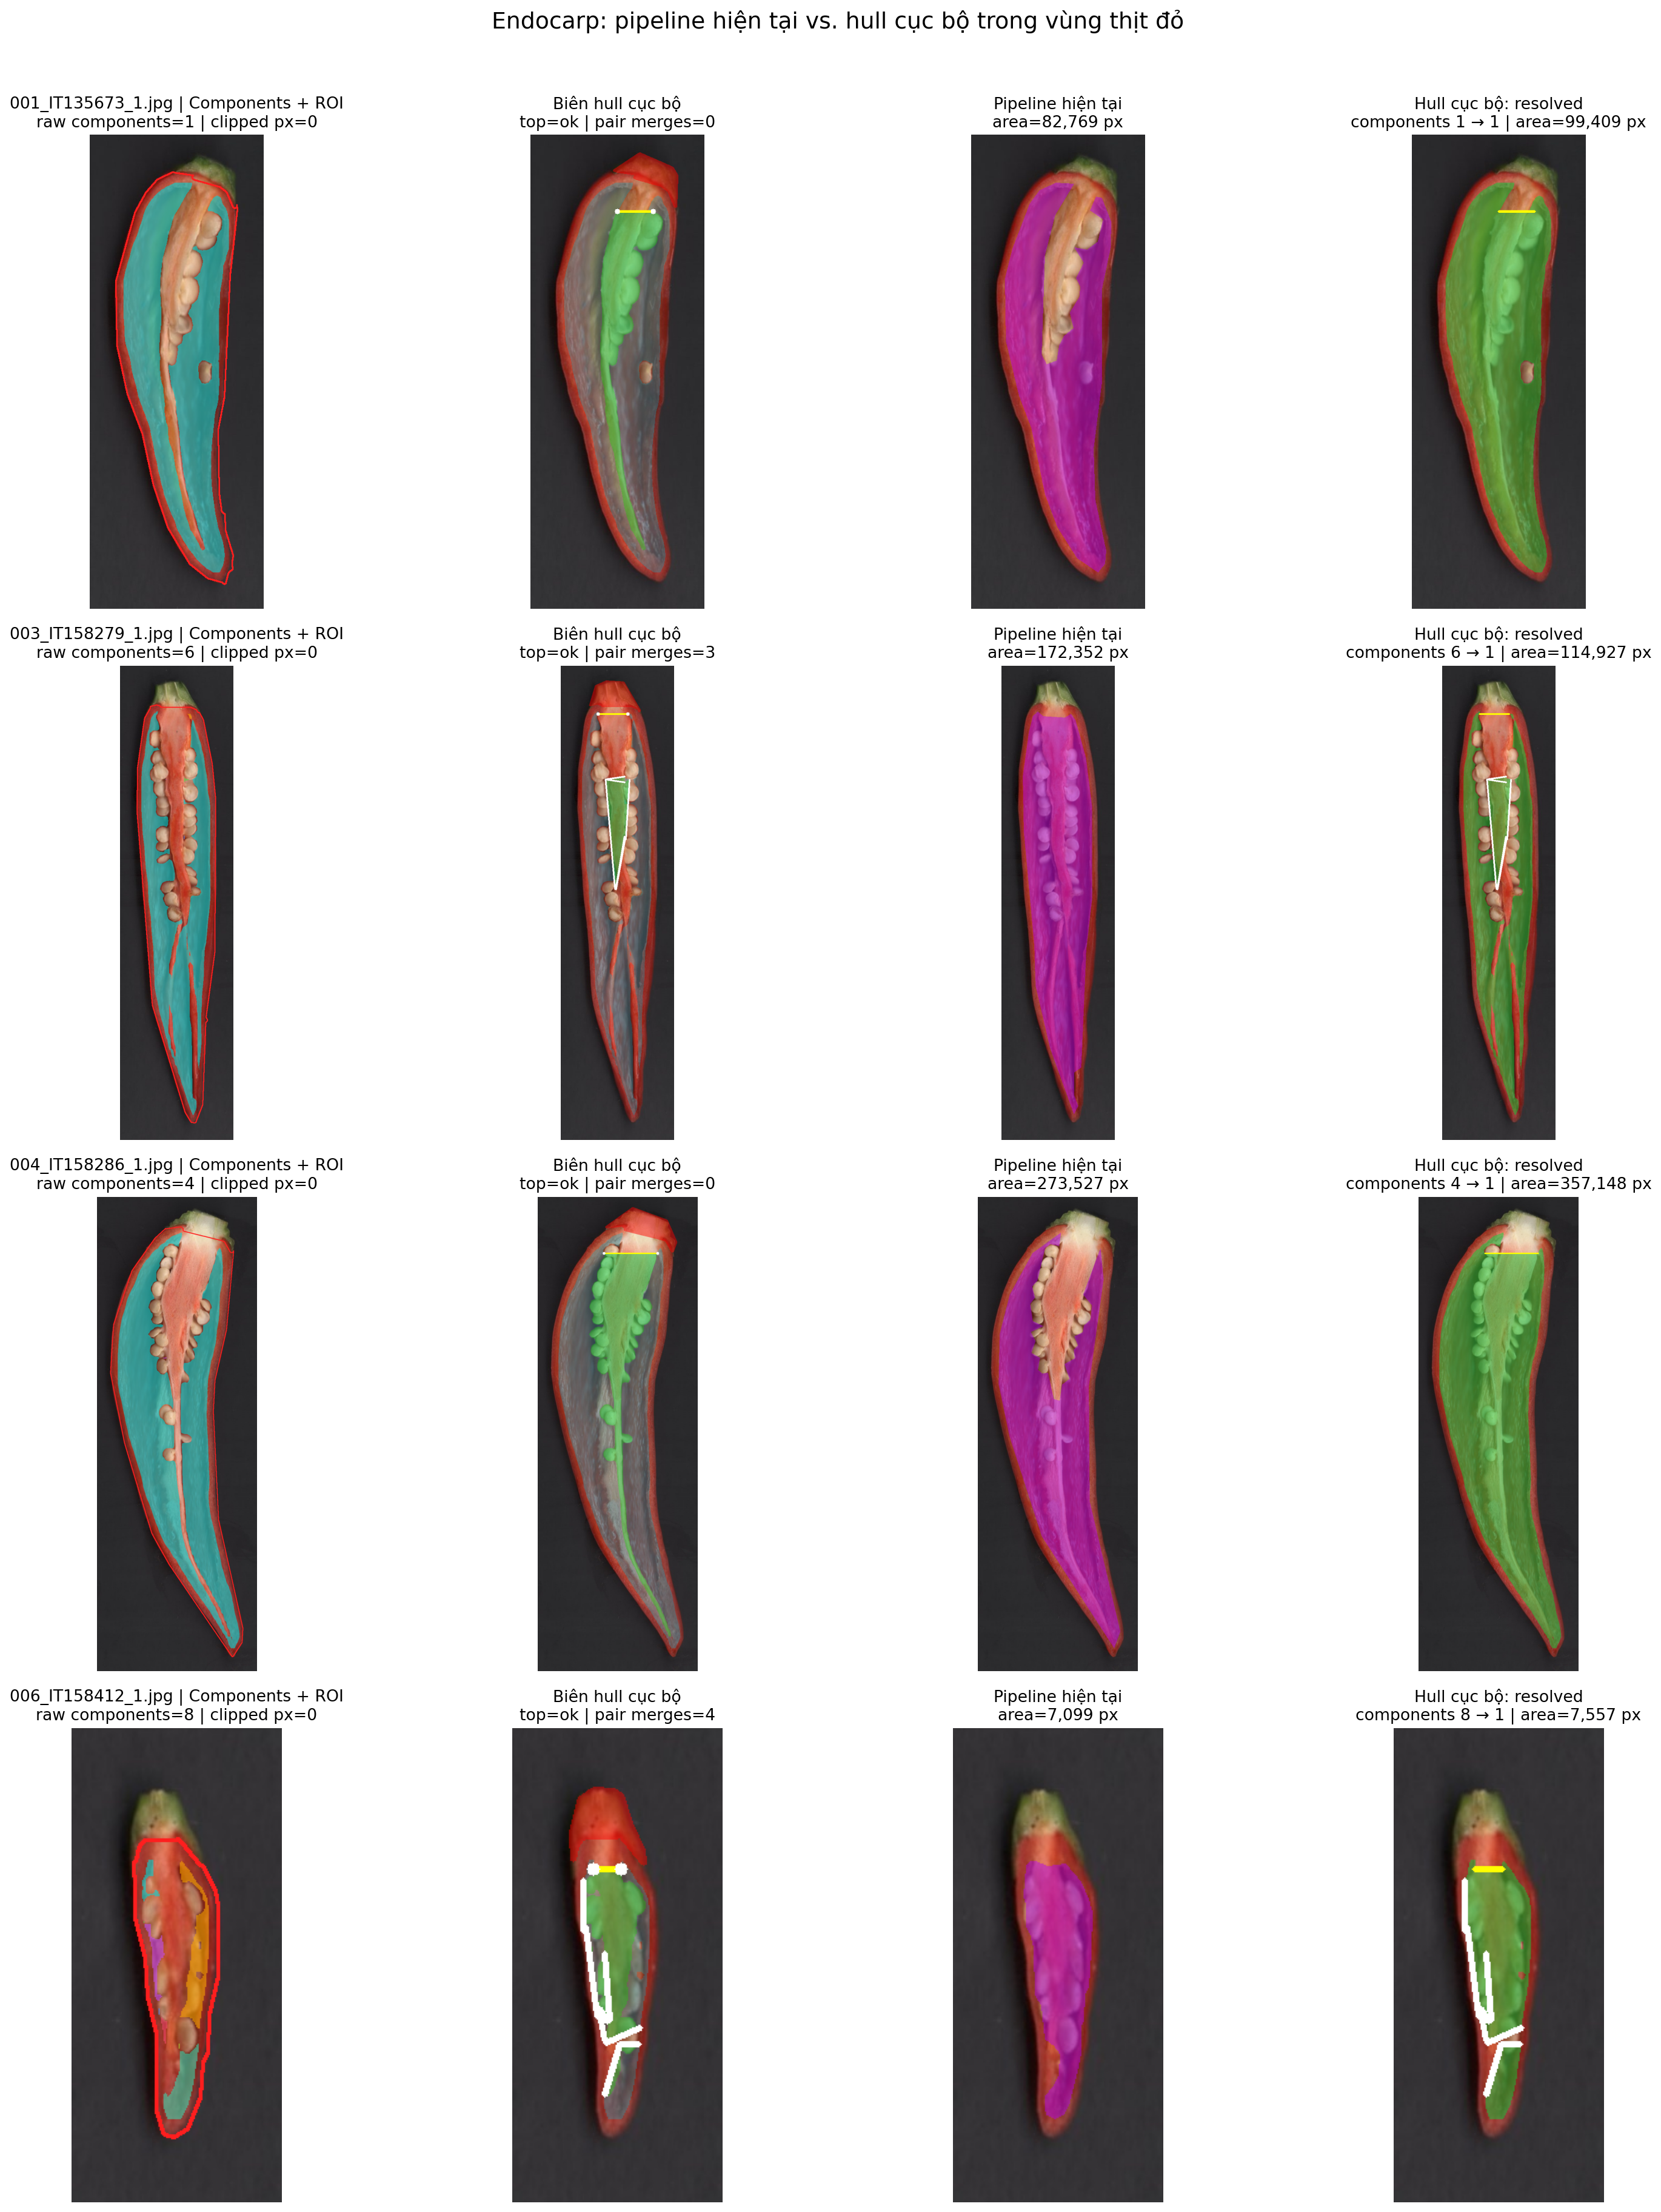

Metrics: [`runs/endocarp_straight_bridge/metrics_4_data_images.csv`](runs/endocarp_straight_bridge/metrics_4_data_images.csv)
